# Segmentación exploratoria de parroquias con K-Means

## Contexto y objetivo

Este notebook agrupa parroquias del Ecuador según el perfil histórico de incidentes reportados. La unidad de análisis es la parroquia y las variables resumen describen su volumen y variabilidad mensual. K-Means es un método **no supervisado**: encuentra grupos parecidos, pero no aprende una etiqueta verdadera de peligrosidad ni pronostica incidentes futuros.

Los nombres **baja, media y alta incidencia relativa** se asignan después de agrupar, ordenando los grupos por su promedio de incidentes mensuales. No son niveles oficiales de seguridad. Los incidentes reportados no equivalen a riesgo individual: no se dispone de población expuesta, cantidad de turistas, subregistro ni coordenadas geográficas.

El archivo preparado tiene aproximadamente 2.33 GB y 17.68 millones de filas. Se procesará por bloques y se agregarán registros mensuales por provincia, cantón y parroquia. No se generan archivos auxiliares: tablas, métricas y gráficos se muestran dentro del notebook.

## Estrategia

1. Leer únicamente las columnas geográficas y temporales necesarias, mediante bloques; sumar incidentes por parroquia y mes.
2. Ajustar la segmentación con el período común **julio de 2021–diciembre de 2023**. Usar solo parroquias con al menos 24 meses de historia registrada al cierre de 2023, para no construir ceros ficticios antes de su primera aparición.
3. Resumir cada parroquia mediante media, desviación, máximo, proporción de meses sin reportes y promedios por mes calendario. Aplicar `log1p` a conteos sesgados y estandarizar antes de calcular distancias.
4. Comparar soluciones con k entre 2 y 6 mediante inercia, silhouette y Davies–Bouldin. Elegir la mayor silhouette como criterio exploratorio y revisar también tamaños e interpretabilidad de los grupos.
5. Mostrar perfiles, parroquias representativas, distribuciones y una matriz de calor provincia × grupo. Sin coordenadas, esa matriz no es un mapa geográfico ni permite señalar puntos sobre el territorio.

In [9]:
# Importamos herramientas para análisis, visualización y agrupamiento.
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown
from scipy.cluster.vq import kmeans2
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from sklearn.decomposition import PCA

# Fijamos parámetros reproducibles y un tema legible para las gráficas.
RANDOM_STATE = 42
CHUNK_SIZE = 250_000
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 140)

# Buscamos el archivo en la ruta del proyecto y en rutas relativas comunes.
DATASET_PATH = Path(r'data\processed\dataset_proyecto_preparado.csv')
if not DATASET_PATH.exists():
    candidates = [
        Path.cwd() / 'data' / 'processed' / 'dataset_proyecto_preparado.csv',
        Path.cwd().parent / 'data' / 'processed' / 'dataset_proyecto_preparado.csv',
    ]
    DATASET_PATH = next((candidate for candidate in candidates if candidate.exists()), DATASET_PATH)

# Informamos la ruta que requiere configuración si el archivo no se encuentra.
if not DATASET_PATH.exists():
    raise FileNotFoundError(f'No se encontró el CSV. Ajuste DATASET_PATH. Ruta revisada: {DATASET_PATH}')

print(f'Archivo: {DATASET_PATH}')
print(f'Tamaño: {DATASET_PATH.stat().st_size / (1024**3):.2f} GB')

Archivo: c:\Users\PAULA\Documents\IntegradorG3\data\processed\dataset_proyecto_preparado.csv
Tamaño: 2.17 GB


## 1. Agregación y cobertura del dataset

El identificador territorial se construye con provincia, cantón y parroquia, en lugar de asumir que el código parroquial es siempre único o numérico. Las filas sin un año o mes válido se contabilizan y excluyen explícitamente.

In [10]:
# Declaramos las columnas mínimas para contar eventos por parroquia y mes.
GEO_COLUMNS = ['provincia', 'Canton', 'Parroquia']
READ_COLUMNS = GEO_COLUMNS + ['Mes', 'Anio']

# Preparamos acumuladores compactos para combinar los conteos de cada bloque.
partial_counts = []
missing_counts = Counter()
year_month_counts = Counter()
total_rows = 0
invalid_period_rows = 0

# Procesamos el archivo en bloques para no cargar los 2.33 GB completos en memoria.
for chunk in pd.read_csv(
    DATASET_PATH,
    usecols=READ_COLUMNS,
    chunksize=CHUNK_SIZE,
    encoding='utf-8-sig',
    low_memory=False,
    dtype={column: 'string' for column in GEO_COLUMNS},
):
    total_rows += len(chunk)
    missing_counts.update(chunk.isna().sum().to_dict())

    # Normalizamos etiquetas geográficas faltantes y espacios en blanco.
    for column in GEO_COLUMNS:
        chunk[column] = chunk[column].fillna('SIN DATO').str.strip().replace('', 'SIN DATO')

    # Convertimos las fechas a valores numéricos y comprobamos su validez.
    chunk['Anio'] = pd.to_numeric(chunk['Anio'], errors='coerce')
    chunk['Mes'] = pd.to_numeric(chunk['Mes'], errors='coerce')
    valid_period = chunk['Anio'].notna() & chunk['Mes'].between(1, 12)
    invalid_period_rows += int((~valid_period).sum())
    valid_chunk = chunk.loc[valid_period].copy()
    valid_chunk['Anio'] = valid_chunk['Anio'].astype('int16')
    valid_chunk['Mes'] = valid_chunk['Mes'].astype('int8')

    # Acumulamos el volumen nacional por año y mes para describir la cobertura.
    year_month_counts.update(valid_chunk.groupby(['Anio', 'Mes'], observed=True).size().to_dict())

    # Reducimos el bloque a conteos por ubicación y período.
    partial = (
        valid_chunk.groupby(GEO_COLUMNS + ['Anio', 'Mes'], observed=True, dropna=False)
        .size()
        .rename('incidentes')
        .reset_index()
    )
    partial_counts.append(partial)

# Consolidamos los conteos parciales en una observación por parroquia y mes.
monthly_counts = (
    pd.concat(partial_counts, ignore_index=True)
    .groupby(GEO_COLUMNS + ['Anio', 'Mes'], as_index=False, observed=True)['incidentes']
    .sum()
)
monthly_counts['period'] = pd.PeriodIndex(
    pd.to_datetime(dict(year=monthly_counts['Anio'], month=monthly_counts['Mes'], day=1)), freq='M'
)

print(f'Filas leídas: {total_rows:,}')
print(f'Filas con año/mes inválido excluidas: {invalid_period_rows:,}')
print(f'Combinaciones parroquia-mes con reportes: {len(monthly_counts):,}')
print(f'Ubicaciones territoriales distintas: {monthly_counts[GEO_COLUMNS].drop_duplicates().shape[0]:,}')
print(f'Cobertura global: {monthly_counts["period"].min()} a {monthly_counts["period"].max()}')
display(pd.DataFrame({'columna': list(missing_counts), 'faltantes': list(missing_counts.values())}))

Filas leídas: 17,680,253
Filas con año/mes inválido excluidas: 0
Combinaciones parroquia-mes con reportes: 61,774
Ubicaciones territoriales distintas: 1,053
Cobertura global: 2021-07 a 2026-08


,columna,faltantes
0,provincia,0
1,Canton,0
2,Parroquia,0
3,Mes,0
4,Anio,0


## 2. Inspección temporal y geográfica

La matriz de cobertura ayuda a separar años completos de períodos parciales. El gráfico por mes es agregado a nivel nacional: no debe confundirse con una tasa de riesgo, porque los conteos absolutos no se ajustan por exposición.

Mes,1,2,3,4,5,6,7,8,9,10,11,12
Anio,,,,,,,,,,,,
2021,0,0,0,0,0,0,314507,319989,307665,327820,299013,334055
2022,304575,294034,312801,311739,318799,291802,309337,296460,294140,306756,287294,302367
2023,286435,270613,289472,289411,291364,290245,295384,284365,287146,289047,273956,299651
2024,208194,276844,291219,271992,278104,277077,268289,269571,279947,294494,279589,297323
2025,267790,244669,277160,263466,277968,271175,268119,275442,267225,266910,269066,289009
2026,267009,250314,282649,268763,290974,268513,260280,280867,0,0,0,0


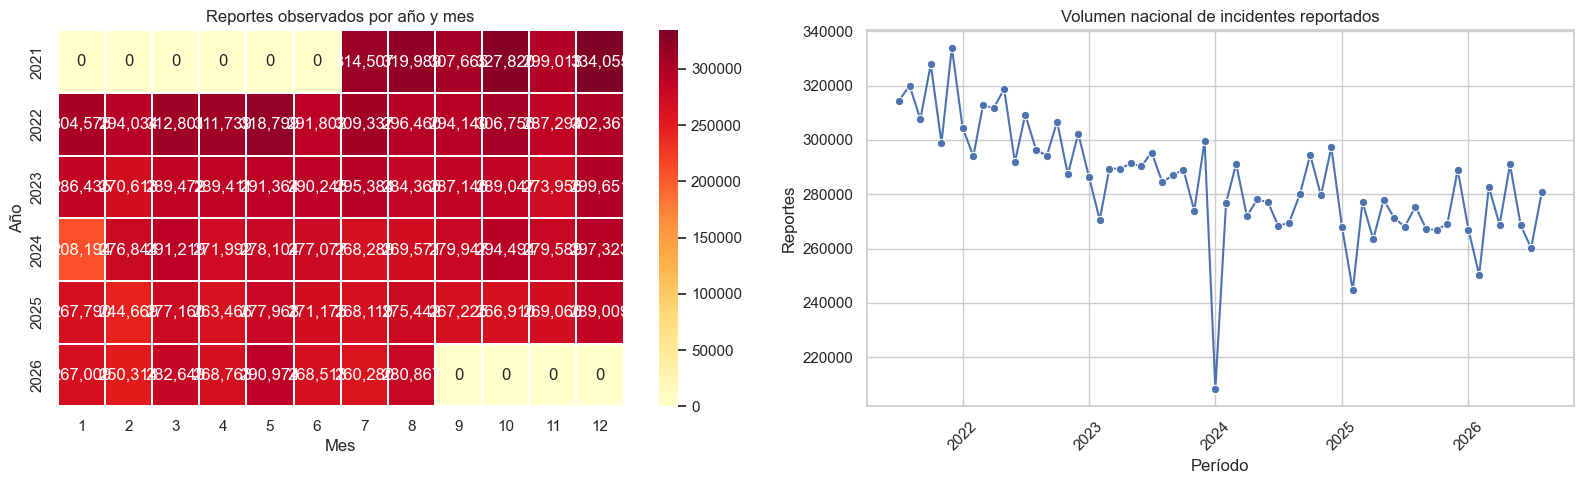

,provincia,incidentes
0,PICHINCHA,4351953
1,GUAYAS,4259613
2,AZUAY,975992
3,MANABI,878137
4,LOS RIOS,784872
5,EL ORO,763942
6,TUNGURAHUA,748836
7,IMBABURA,628233
8,SANTO DOMINGO DE LOS TSACHILAS,608666
9,CHIMBORAZO,501471


In [11]:
# Reorganizamos el total de reportes para revisar meses observados y períodos parciales.
coverage = (
    pd.Series(year_month_counts, name='incidentes')
    .rename_axis(['Anio', 'Mes'])
    .reset_index()
    .pivot(index='Anio', columns='Mes', values='incidentes')
    .reindex(columns=range(1, 13))
    .fillna(0)
    .astype('int64')
)
display(coverage)

# Graficamos la cobertura y el volumen total por período.
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(coverage, cmap='YlOrRd', annot=True, fmt=',.0f', linewidths=0.3, ax=axes[0])
axes[0].set_title('Reportes observados por año y mes')
axes[0].set_xlabel('Mes')
axes[0].set_ylabel('Año')

national_monthly = pd.Series(year_month_counts, name='incidentes').rename_axis(['Anio', 'Mes']).reset_index()
national_monthly['period_date'] = pd.to_datetime(dict(year=national_monthly['Anio'], month=national_monthly['Mes'], day=1))
sns.lineplot(data=national_monthly, x='period_date', y='incidentes', marker='o', ax=axes[1])
axes[1].set_title('Volumen nacional de incidentes reportados')
axes[1].set_xlabel('Período')
axes[1].set_ylabel('Reportes')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()

# Mostramos provincias con mayor volumen acumulado como referencia descriptiva.
province_totals = (
    monthly_counts.groupby('provincia', as_index=False, observed=True)['incidentes']
    .sum()
    .sort_values('incidentes', ascending=False)
)
display(province_totals.head(15).reset_index(drop=True))

## 3. Construcción de perfiles de parroquia

La segmentación se ajusta únicamente con observaciones de julio de 2021 a diciembre de 2023. Para evitar atribuir ceros anteriores a la primera evidencia de una ubicación, cada parroquia debe tener al menos 24 meses desde su primer registro hasta el cierre del período de entrenamiento. Los datos parciales de 2021 y 2026 no se usan para construir los perfiles.

In [12]:
# Definimos el período histórico común para construir los grupos sin incorporar observaciones posteriores.
TRAIN_START = pd.Period('2021-07', freq='M')
TRAIN_END = pd.Period('2023-12', freq='M')
training_months = pd.period_range(TRAIN_START, TRAIN_END, freq='M')
training_observations = monthly_counts.loc[monthly_counts['period'].between(TRAIN_START, TRAIN_END)].copy()

# Determinamos el primer mes registrado para cada ubicación.
first_reporting = (
    training_observations.groupby(GEO_COLUMNS, as_index=False, observed=True)['period']
    .min()
    .rename(columns={'period': 'first_reporting_period'})
)
first_reporting_ordinals = pd.PeriodIndex(first_reporting['first_reporting_period'], freq='M').asi8
first_reporting['months_available'] = TRAIN_END.ordinal - first_reporting_ordinals + 1
eligible_locations = first_reporting.loc[first_reporting['months_available'] >= 24].copy()

# Combinamos ubicaciones elegibles y calendario de entrenamiento para representar meses sin reportes con cero.
calendar = pd.DataFrame({'period': training_months})
panel = eligible_locations[GEO_COLUMNS].merge(calendar, how='cross')
panel = panel.merge(eligible_locations[GEO_COLUMNS + ['first_reporting_period']], on=GEO_COLUMNS, how='left', validate='many_to_one')
panel = panel.loc[panel['period'] >= panel['first_reporting_period']].copy()
panel = panel.merge(
    training_observations[GEO_COLUMNS + ['period', 'incidentes']],
    on=GEO_COLUMNS + ['period'],
    how='left',
    validate='one_to_one',
)
panel['incidentes'] = panel['incidentes'].fillna(0).astype('float32')
panel['Mes'] = panel['period'].dt.month.astype('int8')

# Resumimos volumen, volatilidad, meses sin reportes y picos mensuales por parroquia.
summary_profile = (
    panel.groupby(GEO_COLUMNS, observed=True)
    .agg(
        media_mensual=('incidentes', 'mean'),
        desviacion_mensual=('incidentes', 'std'),
        proporcion_meses_cero=('incidentes', lambda values: (values == 0).mean()),
        maximo_mensual=('incidentes', 'max'),
        meses_con_historia=('incidentes', 'size'),
    )
    .reset_index()
)
summary_profile['desviacion_mensual'] = summary_profile['desviacion_mensual'].fillna(0)

# Incorporamos promedios por mes calendario para representar diferencias estacionales.
seasonal_profile = (
    panel.groupby(GEO_COLUMNS + ['Mes'], observed=True)['incidentes']
    .mean()
    .unstack('Mes')
    .reindex(columns=range(1, 13))
    .fillna(0)
)
seasonal_profile.columns = [f'media_mes_{month:02d}' for month in seasonal_profile.columns]
profiles = summary_profile.merge(seasonal_profile.reset_index(), on=GEO_COLUMNS, how='inner', validate='one_to_one')
print(f'Ubicaciones con al menos 24 meses de historia: {len(eligible_locations):,} de {len(first_reporting):,}')
print(f'Filas del panel de entrenamiento: {len(panel):,}')
display(profiles.head())

Ubicaciones con al menos 24 meses de historia: 1,048 de 1,051
Filas del panel de entrenamiento: 31,308


,provincia,Canton,Parroquia,media_mensual,desviacion_mensual,proporcion_meses_cero,maximo_mensual,meses_con_historia,media_mes_01,media_mes_02,media_mes_03,media_mes_04,media_mes_05,media_mes_06,media_mes_07,media_mes_08,media_mes_09,media_mes_10,media_mes_11,media_mes_12
0,0,0,0,0.533333,2.921187,0.966667,16.0,30,0.0,0.0,0.0,0.0,0.0,0.0,5.333333,0.000000,0.000000,0.000000,0.000000,0.000000
1,AZUAY,CAMILO PONCE ENRIQUEZ,"CAMILO PONCE ENRÍQUEZ, CABECERA CANTONAL",311.433319,42.036671,0.000000,450.0,30,273.0,283.0,389.0,290.0,282.0,312.5,317.000000,304.666656,327.000000,302.000000,295.333344,348.666656
2,AZUAY,CAMILO PONCE ENRIQUEZ,EL CARMEN DE PIJILÍ,5.833333,2.889736,0.000000,11.0,30,6.5,6.5,3.5,3.0,5.0,3.5,7.333333,5.666667,5.333333,5.666667,6.333333,9.333333
3,AZUAY,CHORDELEG,"CHORDELEG, CABECERA CANTONAL",65.300003,11.826767,0.000000,91.0,30,71.0,65.0,61.5,66.0,56.0,58.5,72.000000,55.666668,66.000000,67.000000,68.000000,72.333336
4,AZUAY,CHORDELEG,LA UNIÓN,9.533334,5.563014,0.000000,23.0,30,12.0,6.5,10.5,7.5,11.0,7.5,11.666667,7.000000,14.333333,9.333333,9.333333,7.000000


## 4. Transformación, selección de k y métricas de agrupamiento

La transformación logarítmica reduce el dominio de unos pocos conteos extremos antes de estandarizar. Silhouette resume cohesión y separación (más alto es mejor); Davies–Bouldin compara dispersión y separación (más bajo suele ser mejor); la inercia disminuye al aumentar k y sirve principalmente para observar el codo. Ninguna métrica determina por sí sola qué nivel es útil para una política de seguridad.

,k,inercia,silhouette,davies_bouldin
0,2,6633.0716,0.5365,0.6421
1,3,4012.1855,0.4771,0.6626
2,4,2726.4548,0.4760,0.6564
3,5,1788.5073,0.4845,0.6226
4,6,1339.0494,0.4706,0.6117


k seleccionado por silhouette máxima: 2


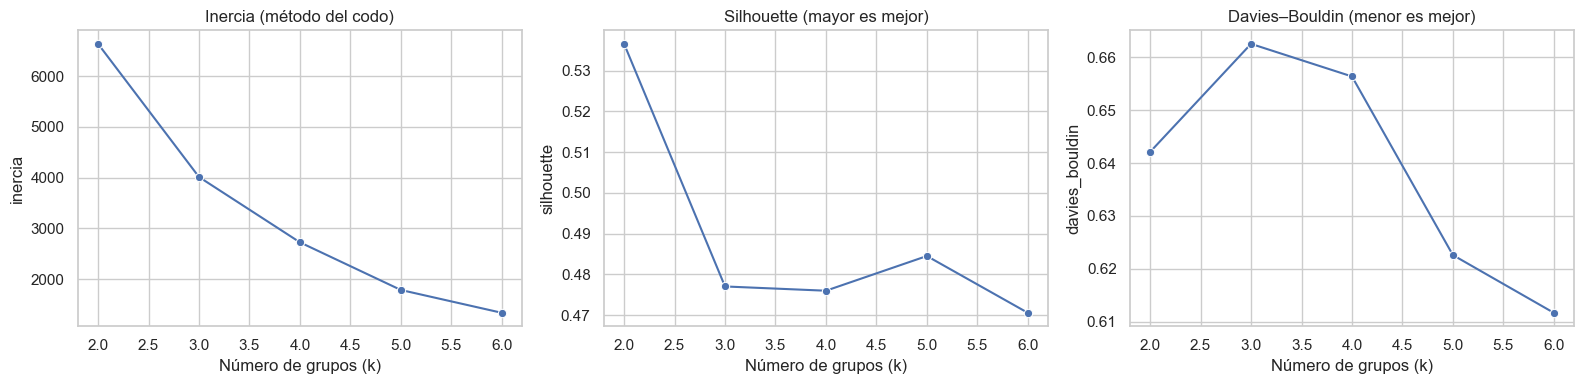

In [13]:
# Seleccionamos variables resumen y promedios mensuales para los perfiles territoriales.
SUMMARY_FEATURES = ['media_mensual', 'desviacion_mensual', 'proporcion_meses_cero', 'maximo_mensual']
SEASONAL_FEATURES = [f'media_mes_{month:02d}' for month in range(1, 13)]
COUNT_FEATURES = ['media_mensual', 'desviacion_mensual', 'maximo_mensual'] + SEASONAL_FEATURES
FEATURE_COLUMNS = SUMMARY_FEATURES + SEASONAL_FEATURES
profile_features = profiles[FEATURE_COLUMNS].copy()

# Aplicamos log1p a los conteos y dejamos la proporción de meses cero en su escala natural.
profile_features[COUNT_FEATURES] = np.log1p(profile_features[COUNT_FEATURES].clip(lower=0))

# Estandarizamos los perfiles para que una variable de escala grande no domine las distancias.
scaler = StandardScaler()
scaled_profiles = scaler.fit_transform(profile_features)

# Evaluamos soluciones reproducibles para cantidades razonables de grupos.
candidate_ks = range(2, min(7, len(profiles)))
if len(candidate_ks) == 0:
    raise ValueError('Se requieren al menos tres parroquias elegibles para comparar soluciones K-Means.')
cluster_results = []
candidate_models = {}
silhouette_sample_size = min(10_000, len(profiles) - 1)
for k in candidate_ks:
    centroids, candidate_labels = kmeans2(scaled_profiles, k, minit='++', iter=100, seed=RANDOM_STATE)
    silhouette = silhouette_score(
        scaled_profiles,
        candidate_labels,
        sample_size=silhouette_sample_size,
        random_state=RANDOM_STATE,
    )
    db_score = davies_bouldin_score(scaled_profiles, candidate_labels)
    inertia = np.square(scaled_profiles - centroids[candidate_labels]).sum()
    cluster_results.append({'k': k, 'inercia': inertia, 'silhouette': silhouette, 'davies_bouldin': db_score})
    candidate_models[k] = (centroids, candidate_labels)

# Ordenamos las métricas para comparar cohesión, separación y ganancia de inercia.
cluster_metrics = pd.DataFrame(cluster_results).sort_values('k').reset_index(drop=True)
display(cluster_metrics.round(4))
best_k = int(cluster_metrics.loc[cluster_metrics['silhouette'].idxmax(), 'k'])
selected_centroids, cluster_labels = candidate_models[best_k]
print(f'k seleccionado por silhouette máxima: {best_k}')

# Graficamos las métricas para exponer la decisión de selección de k.
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.lineplot(data=cluster_metrics, x='k', y='inercia', marker='o', ax=axes[0])
axes[0].set_title('Inercia (método del codo)')
sns.lineplot(data=cluster_metrics, x='k', y='silhouette', marker='o', ax=axes[1])
axes[1].set_title('Silhouette (mayor es mejor)')
sns.lineplot(data=cluster_metrics, x='k', y='davies_bouldin', marker='o', ax=axes[2])
axes[2].set_title('Davies–Bouldin (menor es mejor)')
for axis in axes:
    axis.set_xlabel('Número de grupos (k)')
plt.tight_layout()
plt.show()

## 5. Perfil de grupos y etiqueta de incidencia relativa

Los números de cluster son identificadores arbitrarios. Para facilitar la lectura, se ordenan por media mensual del grupo y se asignan nombres descriptivos relativos. Si hay dos grupos, se usan baja y alta; si hay tres o más, los extremos se llaman baja y alta y los restantes media.

,cluster,nivel_relativo,parroquias,media_incidentes_mensual,desviacion_mensual_promedio,proporcion_meses_cero,pico_mensual_promedio
0,1,Baja incidencia relativa,621,12.94600,4.317000,0.075,23.554001
1,0,Alta incidencia relativa,427,682.21698,67.355003,0.000,818.304016


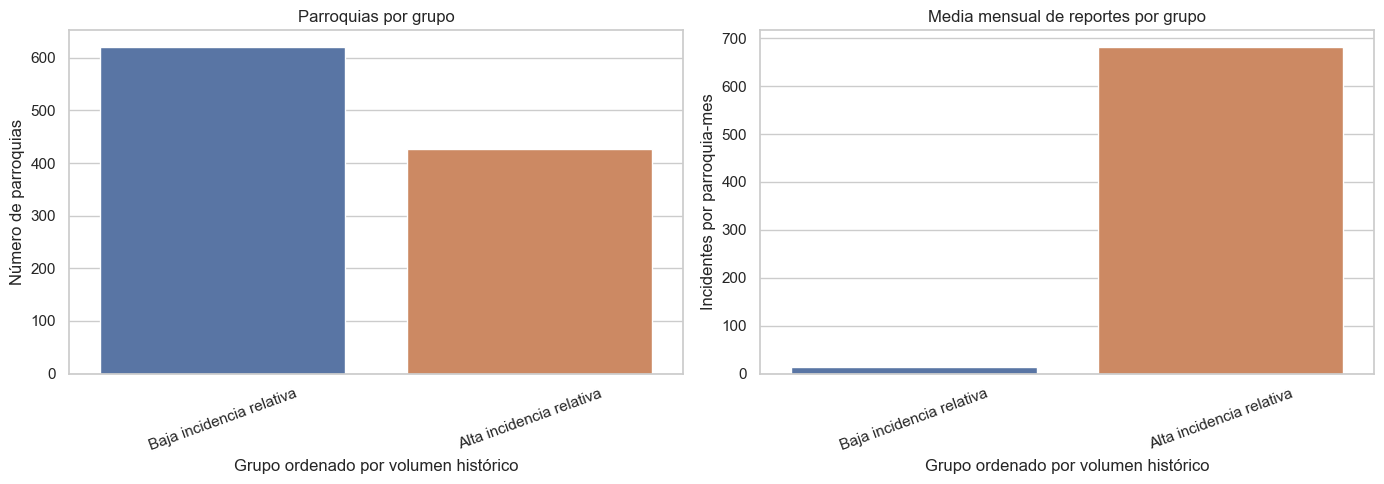

In [14]:
# Adjuntamos al perfil de cada parroquia el cluster obtenido por K-Means.
profiles['cluster'] = cluster_labels

# Resumimos los grupos en la escala original de incidentes reportados.
cluster_summary = (
    profiles.groupby('cluster', as_index=False, observed=True)
    .agg(
        parroquias=('media_mensual', 'size'),
        media_incidentes_mensual=('media_mensual', 'mean'),
        desviacion_mensual_promedio=('desviacion_mensual', 'mean'),
        proporcion_meses_cero=('proporcion_meses_cero', 'mean'),
        pico_mensual_promedio=('maximo_mensual', 'mean'),
    )
    .sort_values('media_incidentes_mensual')
    .reset_index(drop=True)
)

# Asignamos nombres relativos según el orden de la media, no como etiquetas oficiales de seguridad.
if len(cluster_summary) == 2:
    relative_names = ['Baja incidencia relativa', 'Alta incidencia relativa']
else:
    relative_names = []
    for rank in range(len(cluster_summary)):
        if rank == 0:
            relative_names.append('Baja incidencia relativa')
        elif rank == len(cluster_summary) - 1:
            relative_names.append('Alta incidencia relativa')
        else:
            relative_names.append('Incidencia media relativa')
cluster_summary['nivel_relativo'] = relative_names
cluster_name_map = dict(zip(cluster_summary['cluster'], cluster_summary['nivel_relativo']))
profiles['nivel_relativo'] = profiles['cluster'].map(cluster_name_map)
cluster_summary = cluster_summary[['cluster', 'nivel_relativo', 'parroquias', 'media_incidentes_mensual', 'desviacion_mensual_promedio', 'proporcion_meses_cero', 'pico_mensual_promedio']]
display(cluster_summary.round(3))

# Comparamos el tamaño y el volumen mensual de los clusters.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=cluster_summary, x='nivel_relativo', y='parroquias', hue='nivel_relativo', legend=False, ax=axes[0])
axes[0].set_title('Parroquias por grupo')
axes[0].set_xlabel('Grupo ordenado por volumen histórico')
axes[0].set_ylabel('Número de parroquias')
axes[0].tick_params(axis='x', rotation=20)
sns.barplot(data=cluster_summary, x='nivel_relativo', y='media_incidentes_mensual', hue='nivel_relativo', legend=False, ax=axes[1])
axes[1].set_title('Media mensual de reportes por grupo')
axes[1].set_xlabel('Grupo ordenado por volumen histórico')
axes[1].set_ylabel('Incidentes por parroquia-mes')
axes[1].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

## 6. Matrices de calor y parroquias destacadas

La matriz provincia × grupo es un resumen tabular de pertenencias. No representa distancias ni ubicación exacta. Los rankings corresponden al promedio mensual del período analizado y no se ajustan por población, turistas u otros denominadores.

nivel_relativo,Baja incidencia relativa,Alta incidencia relativa
provincia,,
GUAYAS,7,47
PICHINCHA,15,46
MANABI,43,33
AZUAY,47,29
TUNGURAHUA,25,28
LOS RIOS,5,25
EL ORO,40,23
IMBABURA,23,19
COTOPAXI,23,17


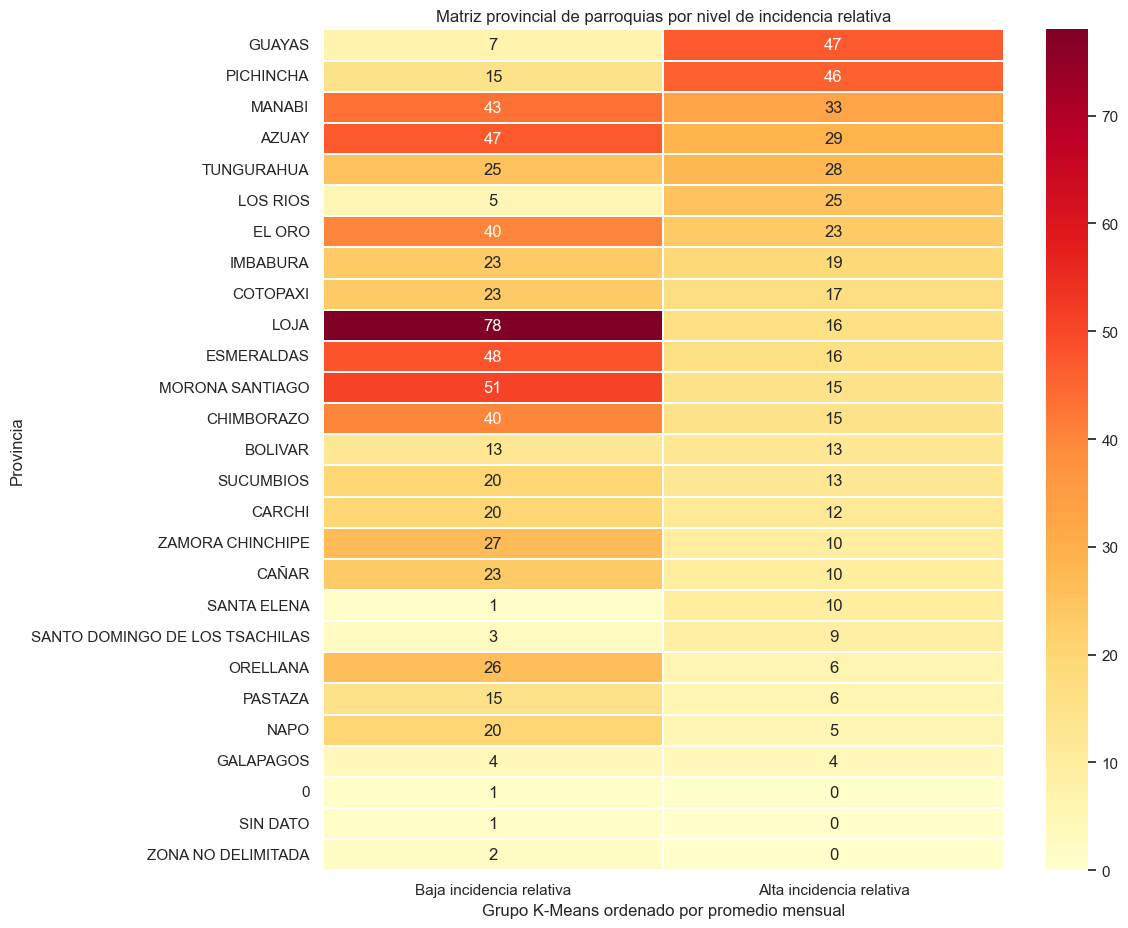

,provincia,Canton,Parroquia,media_mensual,maximo_mensual,nivel_relativo
0,PICHINCHA,QUITO,"QUITO DISTRITO METROPOLITANO, CABECERA CANTONA...",49825.261719,56330.0,Alta incidencia relativa
1,GUAYAS,GUAYAQUIL,"GUAYAQUIL, CABECERA CANTONAL Y CAPITAL PROVINCIAL",48364.859375,59299.0,Alta incidencia relativa
2,AZUAY,CUENCA,"CUENCA, CABECERA CANTONAL Y CAPITAL PROVINCIAL.",11885.870117,13555.0,Alta incidencia relativa
3,SANTO DOMINGO DE LOS TSACHILAS,SANTO DOMINGO,"SANTO DOMINGO DE LOS COLORADOS, CABECERA CANTO...",8776.830078,9655.0,Alta incidencia relativa
4,TUNGURAHUA,AMBATO,"AMBATO, CABECERA CANTONAL Y CAPITAL PROVINCIAL",7764.330078,8528.0,Alta incidencia relativa
5,EL ORO,MACHALA,"MACHALA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",6879.330078,7866.0,Alta incidencia relativa
6,CHIMBORAZO,RIOBAMBA,"RIOBAMBA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",6225.600098,6886.0,Alta incidencia relativa
7,IMBABURA,IBARRA,"SAN MIGUEL DE IBARRA, CABECERA CANTONAL Y CAPI...",6212.229980,6945.0,Alta incidencia relativa
8,LOJA,LOJA,"LOJA, CABECERA CANTONAL Y CAPITAL PROVINCIAL",5471.299805,6204.0,Alta incidencia relativa
9,GUAYAS,DURAN,"ELOY ALFARO (DURÁN), CABECERA CANTONAL",4818.830078,5820.0,Alta incidencia relativa


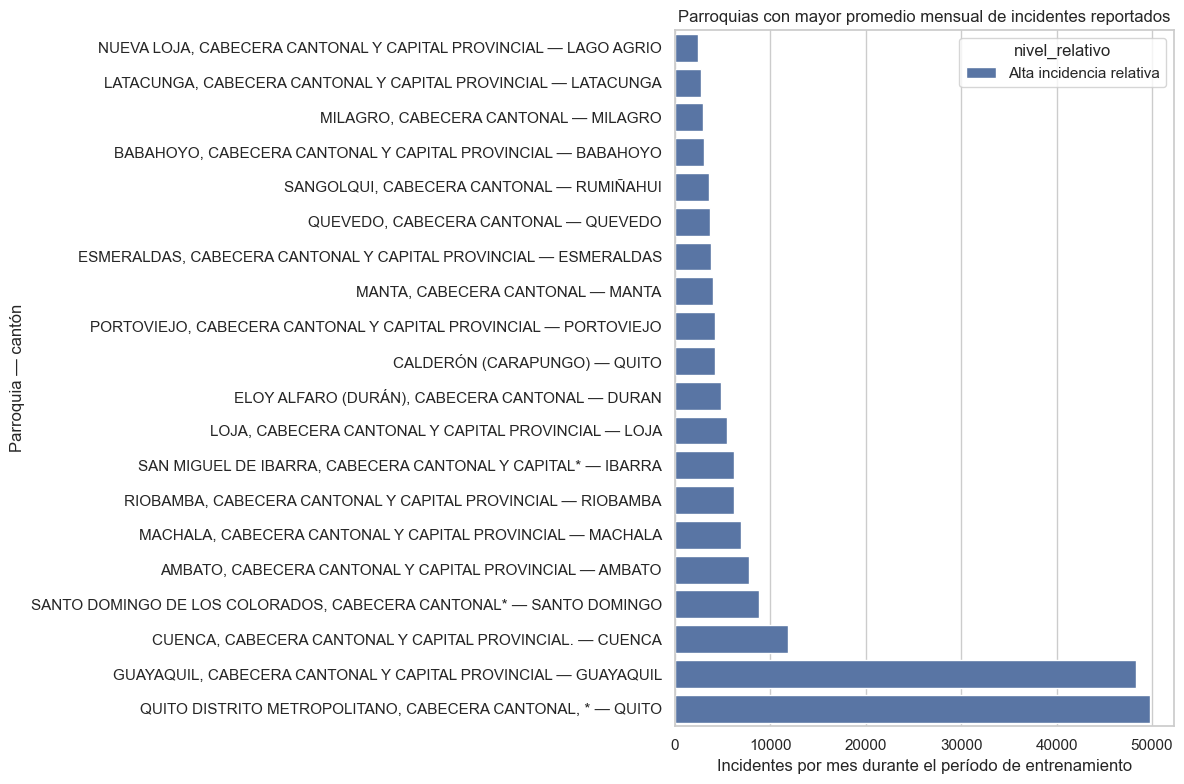

In [15]:
# Calculamos cuántas parroquias de cada provincia pertenecen a cada nivel relativo.
province_cluster_counts = pd.crosstab(profiles['provincia'], profiles['nivel_relativo'])
province_cluster_counts = province_cluster_counts.reindex(columns=cluster_summary['nivel_relativo'], fill_value=0)

# Mostramos las provincias con mayor presencia absoluta en el grupo de incidencia relativa alta.
high_label = cluster_summary.iloc[-1]['nivel_relativo']
province_cluster_counts = province_cluster_counts.sort_values(high_label, ascending=False)
display(province_cluster_counts.head(20))

# Visualizamos una matriz de calor provincial; sus valores son números de parroquias por grupo.
plt.figure(figsize=(12, max(6, min(14, len(province_cluster_counts) * 0.35))))
sns.heatmap(province_cluster_counts, cmap='YlOrRd', annot=True, fmt='d', linewidths=0.3)
plt.title('Matriz provincial de parroquias por nivel de incidencia relativa')
plt.xlabel('Grupo K-Means ordenado por promedio mensual')
plt.ylabel('Provincia')
plt.tight_layout()
plt.show()

# Graficamos las parroquias de mayor promedio y mostramos sus grupos.
top_parishes = profiles.nlargest(20, 'media_mensual').copy()
top_parishes['ubicacion'] = top_parishes['Parroquia'].astype(str) + ' — ' + top_parishes['Canton'].astype(str)
display(top_parishes[['provincia', 'Canton', 'Parroquia', 'media_mensual', 'maximo_mensual', 'nivel_relativo']].reset_index(drop=True).round(2))
plt.figure(figsize=(12, 8))
sns.barplot(data=top_parishes.sort_values('media_mensual'), x='media_mensual', y='ubicacion', hue='nivel_relativo', dodge=False)
plt.title('Parroquias con mayor promedio mensual de incidentes reportados')
plt.xlabel('Incidentes por mes durante el período de entrenamiento')
plt.ylabel('Parroquia — cantón')
plt.tight_layout()
plt.show()

## 7. Visualización de los perfiles y lectura automática

PCA proyecta los perfiles estandarizados a dos dimensiones únicamente para visualización; no altera los clusters usados en las tablas. La separación visual puede perder información de las dimensiones que no se muestran.

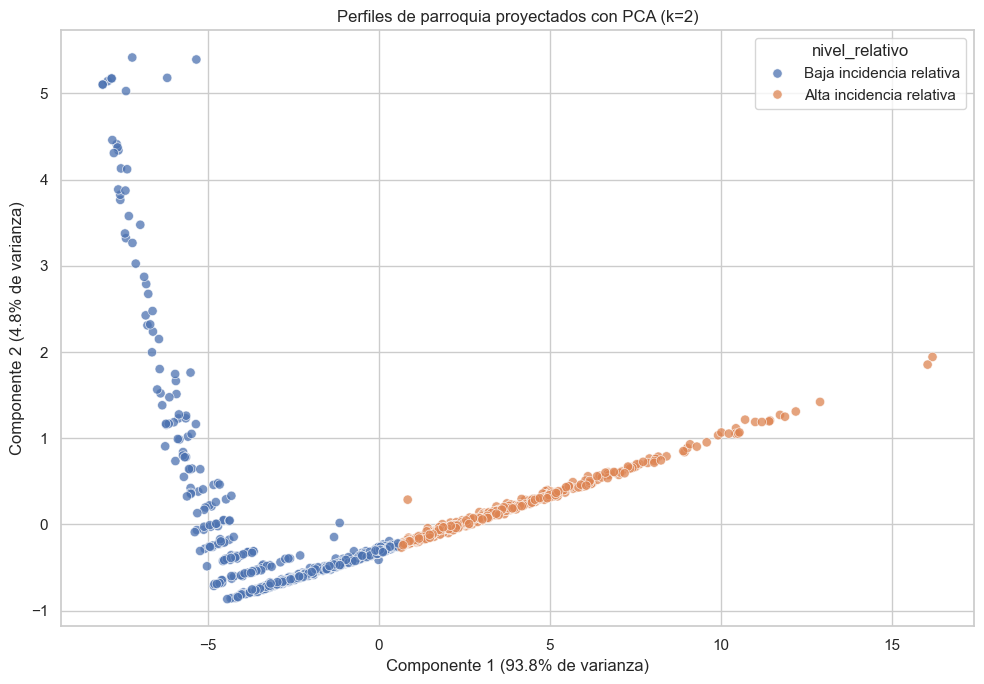

### Resumen sencillo

- Se analizaron **1,048 parroquias** con al menos 24 meses de historia dentro de julio de 2021–diciembre de 2023.
- La solución seleccionada fue **k = 2**, por tener la silhouette más alta entre las alternativas evaluadas (0.537); Davies–Bouldin fue 0.642.
- El grupo de mayor promedio tuvo **427 parroquias** (40.7% del conjunto) y promedió 682.2 reportes por parroquia-mes.
- Estos grupos describen diferencias en los reportes históricos. No demuestran peligrosidad individual ni causalidad.

La selección automática por silhouette es un punto de partida. Antes de definir niveles de alerta, se deben revisar tamaños desbalanceados, calidad del registro y datos de población o flujo turístico.

In [16]:
# Reducimos los perfiles a dos componentes para visualizar la estructura aproximada de los grupos.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
profile_projection = pca.fit_transform(scaled_profiles)
profiles['PCA_1'] = profile_projection[:, 0]
profiles['PCA_2'] = profile_projection[:, 1]

# Graficamos las parroquias por grupo en el espacio proyectado.
plt.figure(figsize=(10, 7))
sns.scatterplot(data=profiles, x='PCA_1', y='PCA_2', hue='nivel_relativo', alpha=0.75, s=45)
plt.title(f'Perfiles de parroquia proyectados con PCA (k={best_k})')
plt.xlabel(f'Componente 1 ({pca.explained_variance_ratio_[0]:.1%} de varianza)')
plt.ylabel(f'Componente 2 ({pca.explained_variance_ratio_[1]:.1%} de varianza)')
plt.tight_layout()
plt.show()

# Generamos una explicación con métricas calculadas en esta ejecución.
selected_metrics = cluster_metrics.loc[cluster_metrics['k'] == best_k].iloc[0]
high_cluster = cluster_summary.iloc[-1]
relative_share = high_cluster['parroquias'] / len(profiles)
display(Markdown(
    f"### Resumen sencillo\n\n"
    f"- Se analizaron **{len(profiles):,} parroquias** con al menos 24 meses de historia dentro de julio de 2021–diciembre de 2023.\n"
    f"- La solución seleccionada fue **k = {best_k}**, por tener la silhouette más alta entre las alternativas evaluadas ({selected_metrics['silhouette']:.3f}); Davies–Bouldin fue {selected_metrics['davies_bouldin']:.3f}.\n"
    f"- El grupo de mayor promedio tuvo **{int(high_cluster['parroquias']):,} parroquias** ({relative_share:.1%} del conjunto) y promedió {high_cluster['media_incidentes_mensual']:.1f} reportes por parroquia-mes.\n"
    f"- Estos grupos describen diferencias en los reportes históricos. No demuestran peligrosidad individual ni causalidad.\n\n"
    "La selección automática por silhouette es un punto de partida. Antes de definir niveles de alerta, se deben revisar tamaños desbalanceados, calidad del registro y datos de población o flujo turístico."
))

## Conclusiones generales y uso responsable

- K-Means segmenta perfiles históricos de parroquias; no es un clasificador supervisado, no predice meses futuros y sus identificadores de grupo no tienen un orden natural.
- Los nombres de incidencia baja, media y alta son relativos al promedio mensual de reportes de las ubicaciones y período incluidos. No deben publicarse como niveles oficiales de peligrosidad sin validación externa.
- Los meses sin reportes se consideran cero únicamente dentro del período posterior al primer registro de cada parroquia y hasta diciembre de 2023. Aun así, el subregistro puede hacer que un cero no equivalga a ausencia real de incidentes.
- La matriz de calor presentada resume parroquias por provincia y grupo. El dataset no contiene latitud ni longitud, así que no permite producir un mapa geográfico de puntos o densidad. Para ese mapa se requiere enriquecer los datos con coordenadas verificadas o límites geográficos de parroquias.
- Para hablar de riesgo relativo para turistas es necesario relacionar reportes con población expuesta, flujo turístico y cobertura/denuncia, además de validar resultados con fuentes locales.

**Conclusión:** este análisis ofrece una segmentación exploratoria reproducible de la incidencia histórica reportada. Sus tablas pueden apoyar la priorización de investigación y prevención, pero no sustituyen una medida de riesgo ni una validación territorial.